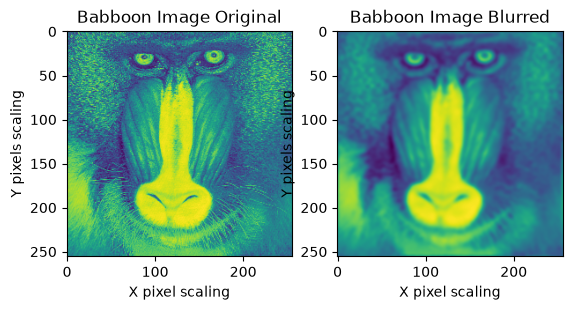

In [1]:
#Computational project optimisation

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from scipy.ndimage import convolve
import proxop

def gaussian_kernel(size=9, sigma=2.0):
    """
    Construct a normalized two-dimensional Gaussian kernel.

    Parameters
    ----------
    size : int
        Size of the square kernel (must be odd).
    sigma : float
        Standard deviation of the Gaussian.

    Returns
    -------
    K : ndarray, shape (size, size)
        Normalized Gaussian kernel.
    """
    coordinates = np.arange(size) - size // 2
    xx, yy = np.meshgrid(coordinates, coordinates)

    K = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    K /= np.sum(K)

    return K


# Gaussian kernel used by the blurring operator
K = gaussian_kernel(size=9, sigma=2.0)


def R(X):
    """
    Apply the Gaussian blurring operator.

    Parameters
    ----------
    X : ndarray, shape (256, 256)
        Input image.

    Returns
    -------
    ndarray, shape (256, 256)
        Blurred image.
    """
    return convolve(X, K, mode="wrap")


def R_adjoint(X):
    """
    Apply the adjoint of the Gaussian blurring operator.

    For a symmetric Gaussian kernel, R_adjoint = R.

    Parameters
    ----------
    X : ndarray, shape (256, 256)
        Input image.

    Returns
    -------
    ndarray, shape (256, 256)
        Result of applying the adjoint operator.
    """
    return convolve(X, np.flip(K), mode="wrap")


def grad(X):
    """
    Compute the discrete gradient using forward differences
    with periodic boundary conditions.

    Parameters
    ----------
    X : ndarray, shape (256, 256)
        Input image.

    Returns
    -------
    ndarray, shape (2, 256, 256)
        First component: differences between neighbouring rows.
        Second component: differences between neighbouring columns.
    """
    G1 = np.roll(X, -1, axis=0) - X
    G2 = np.roll(X, -1, axis=1) - X

    return np.stack((G1, G2), axis=0)


def grad_adjoint(Y):
    """
    Compute the adjoint of the discrete gradient
    with periodic boundary conditions.

    Parameters
    ----------
    Y : ndarray, shape (2, 256, 256)
        Two-component array.

    Returns
    -------
    ndarray, shape (256, 256)
        Result of applying the adjoint gradient operator.
    """
    Y1, Y2 = Y[0], Y[1]

    D1 = np.roll(Y1, 1, axis=0) - Y1
    D2 = np.roll(Y2, 1, axis=1) - Y2

    return D1 + D2


# Part 4 - set up


X = mpimg.imread('babboon.bmp')
X = X.astype(float) / 255
X = np.mean(X, axis = 2)
X_blur = R(X)

plt.subplot(1 , 2 , 1)
plt.title("Babboon Image Original")
plt.xlabel("X pixel scaling")
plt.ylabel("Y pixels scaling")
plt.imshow(X)

plt.subplot(1 ,2 , 2)
plt.title("Babboon Image Blurred")
plt.xlabel("X pixel scaling")
plt.ylabel("Y pixels scaling")
plt.imshow(X_blur)
plt.show()


# Part 5 - Primal Dual

lam = 100


def f(x):
    return 0

def g(y):
    return np.sum(np.abs(y[0])) + np.sum(np.abs(y[1]))

A = grad(X)

def h(x):
    return (lam / 2) * np.linalg.norm(R(x) - X_blur) ** 2

def grad_h(x):
    return lam * R_adjoint(R(x) - X_blur)



x0pd = np.zeros((256, 256))
y0 = np.zeros((2, 256, 256))
gamma = 0.01
sigma = 0.01

for i in range(10 ** 3):

    x_new = x0pd - gamma * grad_h(x0pd) - gamma * grad_adjoint(y0)  #prox_f has no effect for f = 0

    y_input = y0 + sigma * grad(2 * x_new - x0pd)
    y_new = np.minimum(1, np.maximum(y_input, -1))   # prox_g* gives is a indicator function on [-1 , 1]

    x0pd = x_new
    y0 = y_new



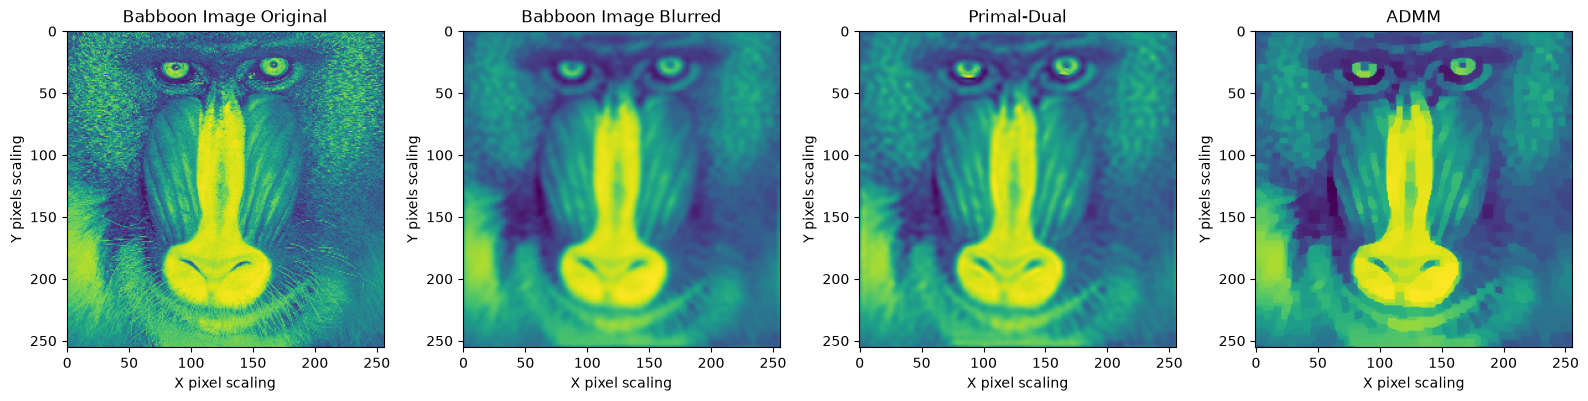

In [2]:
# Part 6 ADMM algorithm

alpha = 2
lam = 200


def grad_aug_lagrangian(x, y, Lam):
    """
    Computing the gradient of a lagrangian:

    grad_L_(x, y, lambda) = lambda R^*(R(x) - X_{\text{blur}}) + alpha gradient^*( gradient_x - y + 1/alpha  * lambda)

    """

    grad_one = lam * R_adjoint(R(x) - X_blur)
    diff = grad(x) - y + (1 / alpha) * Lam
    constant_lambda = alpha * grad_adjoint(diff)

    return grad_one + constant_lambda


x0 = np.zeros((256, 256))
y0 = np.zeros((2, 256, 256))
Lam = np.zeros((2, 256, 256))

for i in range(500):

    x_new = x0.copy()
    gamma = 0.001
    for _ in range(10):
        x_new = x_new - gamma * grad_aug_lagrangian(x_new, y0, Lam)   # gradient descent using lagrangian

        
    v = grad(x_new) + (1.0 / alpha) * Lam    
    y_new = np.sign(v) * np.maximum(0, np.abs(v) - (1.0 / alpha))     # full derivation in the report, use of proximity a operator

    Lam = Lam + alpha * (grad(x_new) - y_new)

    x0 = x_new
    y0 = y_new


plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.title("Babboon Image Original", fontsize=12)
plt.xlabel("X pixel scaling")
plt.ylabel("Y pixels scaling")
plt.imshow(X)

plt.subplot(1, 4, 2)
plt.title("Babboon Image Blurred", fontsize=12)
plt.xlabel("X pixel scaling")
plt.ylabel("Y pixels scaling")
plt.imshow(X_blur)

plt.subplot(1, 4, 3)
plt.title("Primal-Dual", fontsize=12)
plt.xlabel("X pixel scaling")
plt.ylabel("Y pixels scaling")
plt.imshow(x0pd)

plt.subplot(1, 4, 4)
plt.title("ADMM", fontsize=12)
plt.xlabel("X pixel scaling")
plt.ylabel("Y pixels scaling")
plt.imshow(x0)

plt.tight_layout()
plt.show()